**Перед выполнением ячеек переключитесь на среду выполнения с графическим процессором.**

> **Выполнил:** Подольский Филипп, магистратура ПМИ, ФМИ ПГНИУ.
>
> Основная часть выполнена без изменения модели и гиперпараметров преподавателя: VAE 784–256–256–2, 15 эпох на всех
> 60 000 изображениях MNIST (`torchvision.datasets.MNIST`), модель с `latent_dim = 2` для карты латентного
> пространства — 5 эпох, как в заготовке.
>
> Выполнено **задание для самостоятельной работы** (VAE на Fashion-MNIST) и все три пункта «по желанию»: β-VAE с
> β = 0,1 / 1 / 4 / 10, размерность латентного пространства 2 / 5 / 50 и свёрточный VAE; во всех дополнительных
> опытах — тоже по 15 эпох, как в основной части. Для сравнения вариантов на тесте отдельно считаются ошибка
> реконструкции (BCE) и KL-дивергенция, а качество генерации оценивается вспомогательным классификатором цифр
> (какая доля сгенерированных картинок уверенно распознаётся как цифра).
>
> Устройство выбирается в первой ячейке кода (cuda → mps → cpu); прогресс-бары `tqdm` отключены, чтобы не засорять
> сохранённую тетрадку.

In [1]:
%matplotlib inline
# ── Настройки запуска (добавлено при выполнении работы) ──────────────────────────────────────────
# Устройство: cuda -> mps -> cpu. Режим быстрой проверки NN_SMOKE=1: крошечные подвыборки и 1 эпоха
# (в обычном запуске — параметры из задания). Данные и кэши моделей — в папке ../data.
import os
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')   # операции, которых нет в MPS, выполняются на CPU
SMOKE = os.environ.get('NN_SMOKE') == '1'
DATA = '../data'
os.makedirs(DATA, exist_ok=True)
os.environ.setdefault('TORCH_HOME', os.path.abspath(os.path.join(DATA, 'torch_cache')))   # веса torchvision
os.environ.setdefault('HF_HOME', os.path.abspath(os.path.join(DATA, 'hf_cache')))         # модели и датасеты HuggingFace

import torch

def get_device():
    """cuda -> mps -> cpu; переменной окружения NN_DEVICE устройство можно задать явно (например, NN_DEVICE=cpu)."""
    if os.environ.get('NN_DEVICE'):
        return torch.device(os.environ['NN_DEVICE'])
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')

def S(full, smoke):
    """Параметр запуска: значение из задания (full) или уменьшенное для проверки NN_SMOKE=1 (smoke)."""
    return smoke if SMOKE else full

device = get_device()
print(f'Устройство: {device} | режим: {"быстрая проверка (NN_SMOKE=1)" if SMOKE else "полный запуск"}')

Устройство: mps | режим: полный запуск


# **Практическое занятие: Вариационный автоэнкодер (VAE)**

В этом практическом занятии мы реализуем и обучим вариационный автоэнкодер (VAE) на датасете рукописных цифр MNIST. Вы познакомитесь с основными компонентами VAE: энкодером, декодером, репараметризацией и функцией потерь (ELBO). После обучения мы визуализируем результаты: реконструкции, случайные генерации, интерполяции и исследуем влияние гиперпараметров.

👈 *Цель занятия — не просто запустить готовый код, а понять, как устроен VAE внутри, и поэкспериментировать с ним.*

## 1. Импорт библиотек и подготовка данных

Нам понадобятся PyTorch, Torchvision для работы с данными, Matplotlib для визуализации и NumPy.

In [2]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np


# Прогресс-бары отключены (в сохранённой тетрадке они занимают сотни строк)
def tqdm(iterable, **kwargs):
    return iterable

# Для воспроизводимости
torch.manual_seed(42)
np.random.seed(42)

# Устройство (GPU если доступно)
device = get_device()
print(f"Using device: {device}")

Using device: mps


### 1.1 Загрузка датасета MNIST

Мы используем MNIST — 28x28 чёрно-белые изображения цифр. Нормализуем пиксели к интервалу [0,1].

Train size: 60000, Test size: 10000


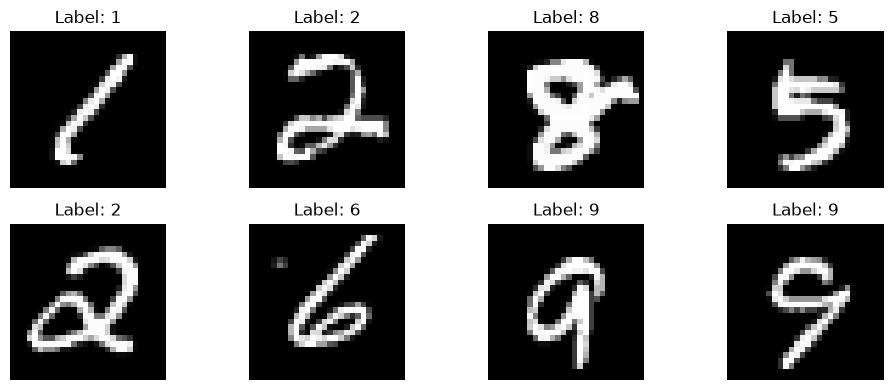

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    # transforms.Normalize((0.5,), (0.5,))  # Не нормализуем, оставляем [0,1] для BCE
])

train_dataset = datasets.MNIST(root=DATA, train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root=DATA, train=False, download=True, transform=transform)
if SMOKE:   # только быстрая проверка: крошечные подвыборки
    train_dataset, test_dataset = Subset(train_dataset, range(1024)), Subset(test_dataset, range(512))

batch_size = 128
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Train size: {len(train_dataset)}, Test size: {len(test_dataset)}")

# Посмотрим на несколько примеров
examples = iter(train_loader)
images, labels = next(examples)
plt.figure(figsize=(10, 4))
for i in range(8):
    plt.subplot(2, 4, i+1)
    plt.imshow(images[i].squeeze(), cmap='gray')
    plt.title(f"Label: {labels[i].item()}")
    plt.axis('off')
plt.tight_layout()
plt.show()

## 2. Определение модели VAE

Класс VAE содержит:
- **Энкодер**: полносвязная сеть, которая преобразует входное изображение (784 пикселя) в параметры распределения $q(z|x)$: среднее `mu` и логарифм дисперсии `log_var`.
- **Reparameterization trick**: позволяет дифференцировать случайный узел: $z = \mu + \sigma \cdot \varepsilon$, где $\varepsilon \sim \mathcal{N}(0, I)$.
- **Декодер**: полносвязная сеть, которая по латентному коду $z$ восстанавливает изображение. На выходе используем сигмоиду, чтобы пиксели были в [0,1].

In [4]:
class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=256, latent_dim=20):
        super(VAE, self).__init__()

        # Энкодер
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2 * latent_dim)  # выход: mu и log_var
        )

        # Декодер
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()  # чтобы выход был в [0,1]
        )

        self.latent_dim = latent_dim

    def encode(self, x):
        """Возвращает mu и log_var"""
        h = self.encoder(x)
        mu, log_var = h.chunk(2, dim=-1)
        return mu, log_var

    def reparameterize(self, mu, log_var):
        """Репараметризация: z = mu + sigma * eps"""
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):
        mu, log_var = self.encode(x)
        z = self.reparameterize(mu, log_var)
        recon = self.decode(z)
        return recon, mu, log_var

### 2.1 Функция потерь (ELBO)

Для VAE мы максимизируем нижнюю границу логарифма правдоподобия (ELBO). На практике минимизируем отрицательный ELBO:

$$ \mathcal{L}_{VAE} = -\mathbb{E}_{z\sim q_\phi(z|x)}[\log p_\theta(x|z)] + D_{KL}(q_\phi(z|x) \| p(z)) $$

где $p(z) = \mathcal{N}(0, I)$. Первое слагаемое — reconstruction loss (BCE или MSE), второе — KL-дивергенция между распределением энкодера и стандартным нормальным.

Для нормальных распределений с диагональной ковариацией KL имеет аналитическую форму:

$$ D_{KL} = -\frac{1}{2} \sum_{j=1}^{M} (1 + \log \sigma_j^2 - \mu_j^2 - \sigma_j^2) $$

In [5]:
def vae_loss(recon_x, x, mu, log_var, beta=1.0):
    """
    recon_x: восстановленное изображение
    x: исходное изображение
    mu, log_var: параметры распределения энкодера
    beta: коэффициент для KL (β-VAE)
    """
    # Reconstruction loss (Binary Cross Entropy, сумма по пикселям и батчу)
    BCE = F.binary_cross_entropy(recon_x, x, reduction='sum')

    # KL divergence
    KL = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())

    # Усредняем по батчу (или можно оставить сумму, главное — консистентность)
    return (BCE + beta * KL) / x.size(0)

## 3. Обучение VAE

Обучим модель на 10-20 эпохах. Будем логировать значения loss и визуализировать прогресс.

In [6]:
# Параметры
latent_dim = 2
hidden_dim = 256
lr = 1e-3
num_epochs = S(15, 1)
beta = 1.0  # для обычного VAE β=1

model = VAE(input_dim=784, hidden_dim=hidden_dim, latent_dim=latent_dim).to(device)
optimizer = optim.Adam(model.parameters(), lr=lr)

train_losses = []
test_losses = []

Epoch 1: Train Loss = 187.7936, Test Loss = 166.2142


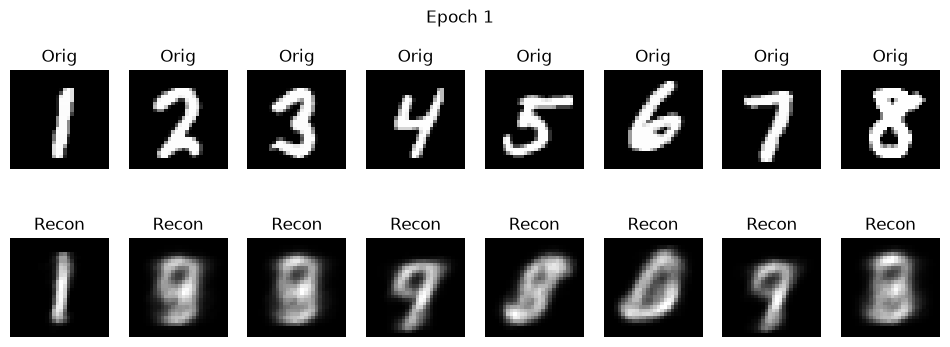

Epoch 2: Train Loss = 161.7919, Test Loss = 158.2120


Epoch 3: Train Loss = 156.3332, Test Loss = 154.6127


Epoch 4: Train Loss = 153.5696, Test Loss = 152.9564


Epoch 5: Train Loss = 151.6519, Test Loss = 150.9279


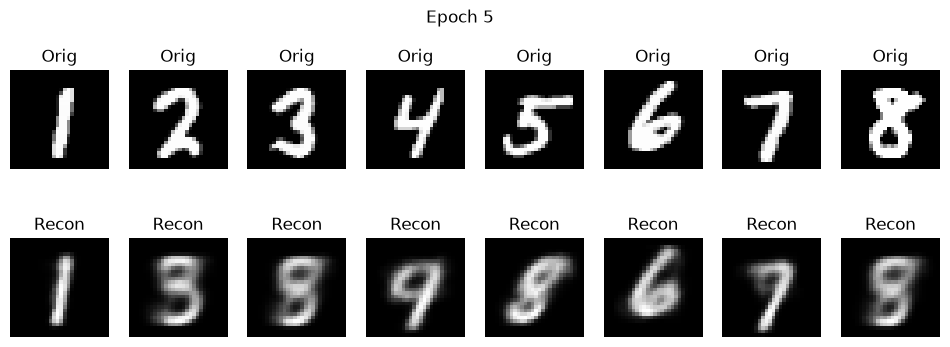

Epoch 6: Train Loss = 150.1894, Test Loss = 149.8693


Epoch 7: Train Loss = 148.8318, Test Loss = 148.9459


Epoch 8: Train Loss = 147.7513, Test Loss = 147.5092


Epoch 9: Train Loss = 146.8348, Test Loss = 147.2530


Epoch 10: Train Loss = 146.0070, Test Loss = 146.2979


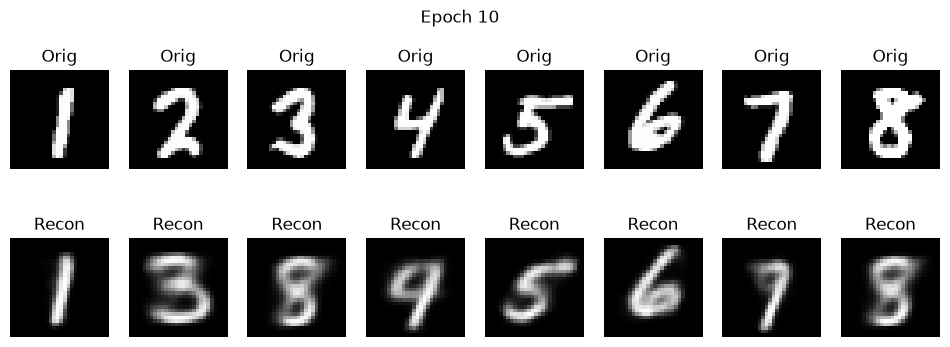

Epoch 11: Train Loss = 145.2609, Test Loss = 146.0617


Epoch 12: Train Loss = 144.8680, Test Loss = 145.1480


Epoch 13: Train Loss = 144.2698, Test Loss = 144.6442


Epoch 14: Train Loss = 143.8287, Test Loss = 144.6243


Epoch 15: Train Loss = 143.3690, Test Loss = 143.9579


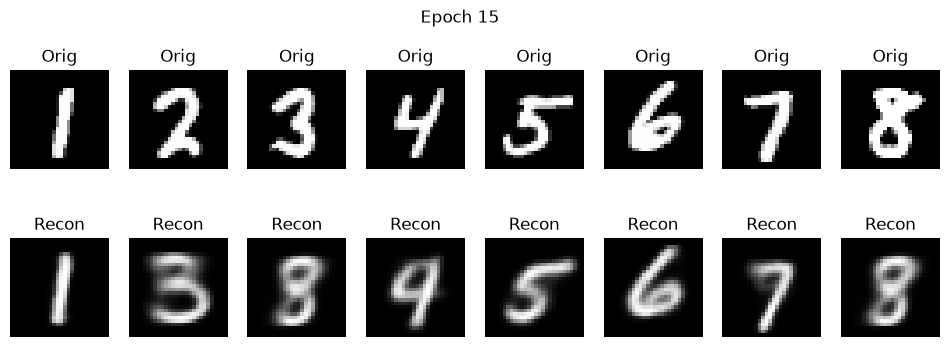

время обучения: 49 с


In [7]:
t0 = time.perf_counter()
for epoch in range(num_epochs):
    model.train()
    total_loss = 0
    for batch_idx, (data, _) in enumerate(tqdm(train_loader, desc=f"Epoch {epoch+1}")):
        data = data.view(data.size(0), -1).to(device)  # flatten
        optimizer.zero_grad()
        recon, mu, log_var = model(data)
        loss = vae_loss(recon, data, mu, log_var, beta)
        loss.backward()
        total_loss += loss.item() * data.size(0)
        optimizer.step()

    avg_train_loss = total_loss / len(train_loader.dataset)
    train_losses.append(avg_train_loss)

    # Оценка на тесте
    model.eval()
    total_test_loss = 0
    with torch.no_grad():
        for data, _ in test_loader:
            data = data.view(data.size(0), -1).to(device)
            recon, mu, log_var = model(data)
            loss = vae_loss(recon, data, mu, log_var, beta)
            total_test_loss += loss.item() * data.size(0)
    avg_test_loss = total_test_loss / len(test_loader.dataset)
    test_losses.append(avg_test_loss)

    print(f'Epoch {epoch+1}: Train Loss = {avg_train_loss:.4f}, Test Loss = {avg_test_loss:.4f}')

    # Визуализируем реконструкции в конце каждой эпохи (первые 8)
    if (epoch+1) % 5 == 0 or epoch == 0:
        model.eval()
        with torch.no_grad():
            sample_data = data[:8]
            recon_sample = recon[:8]
            plt.figure(figsize=(12,4))
            for i in range(8):
                plt.subplot(2,8,i+1)
                plt.imshow(sample_data[i].cpu().view(28,28), cmap='gray')
                plt.axis('off')
                plt.title('Orig')
                plt.subplot(2,8,i+9)
                plt.imshow(recon_sample[i].cpu().view(28,28), cmap='gray')
                plt.axis('off')
                plt.title('Recon')
            plt.suptitle(f'Epoch {epoch+1}')
            plt.show()
print(f'время обучения: {time.perf_counter() - t0:.0f} с')

### 3.1 График обучения

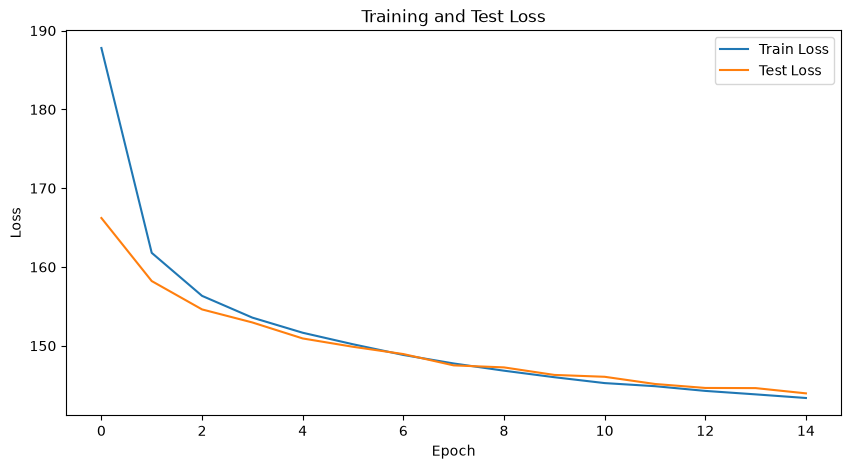

In [8]:
plt.figure(figsize=(10,5))
plt.plot(train_losses, label='Train Loss')
plt.plot(test_losses, label='Test Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.title('Training and Test Loss')
plt.show()

## 4. Генерация новых изображений

Теперь, когда модель обучена, мы можем генерировать новые цифры, просто подавая на вход декодеру случайные векторы $z \sim \mathcal{N}(0, I)$.

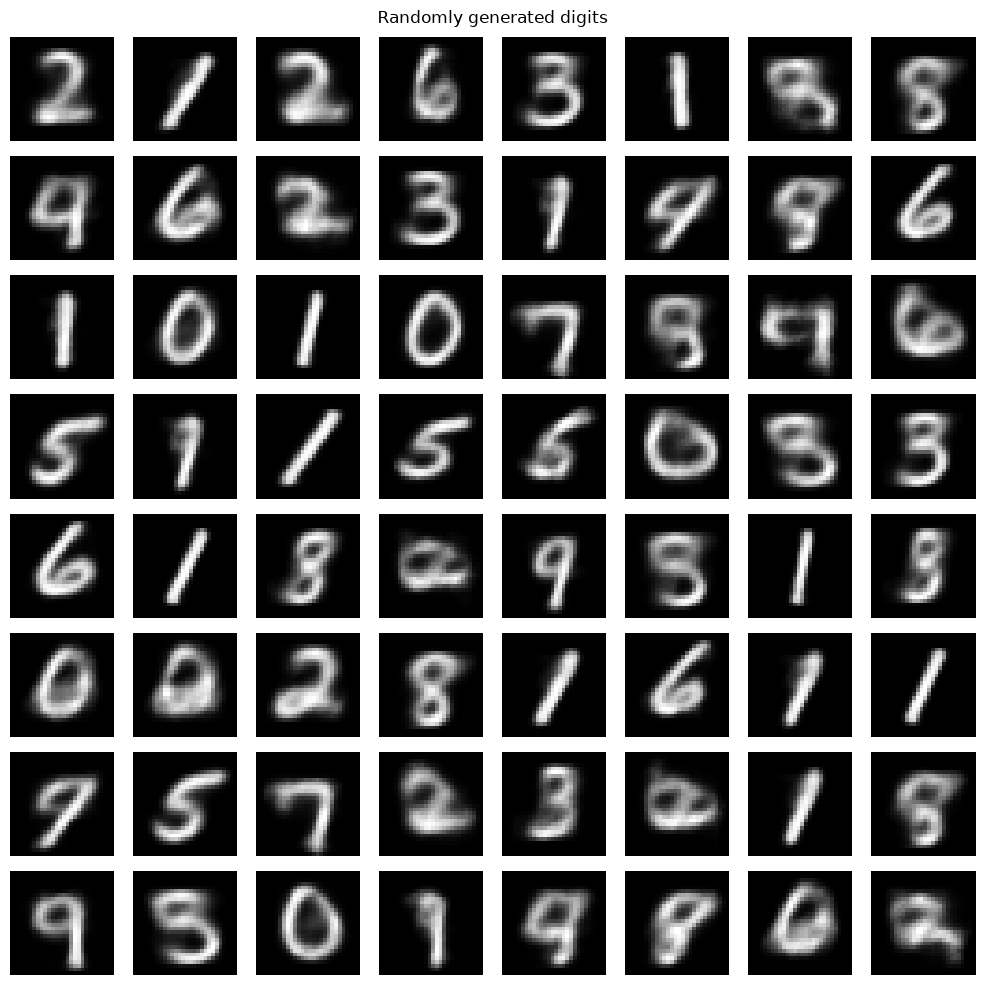

In [9]:
model.eval()
with torch.no_grad():
    # Генерируем 64 случайных z
    z = torch.randn(64, latent_dim).to(device)
    samples = model.decode(z).cpu().view(64, 28, 28)

plt.figure(figsize=(10,10))
for i in range(64):
    plt.subplot(8,8,i+1)
    plt.imshow(samples[i], cmap='gray')
    plt.axis('off')
plt.suptitle('Randomly generated digits')
plt.tight_layout()
plt.show()

## 5. Интерполяция в латентном пространстве

Возьмём два случайных изображения из тестового набора, найдём их латентные коды и линейно проинтерполируем между ними. Подадим промежуточные точки в декодер и посмотрим, как плавно меняется изображение.

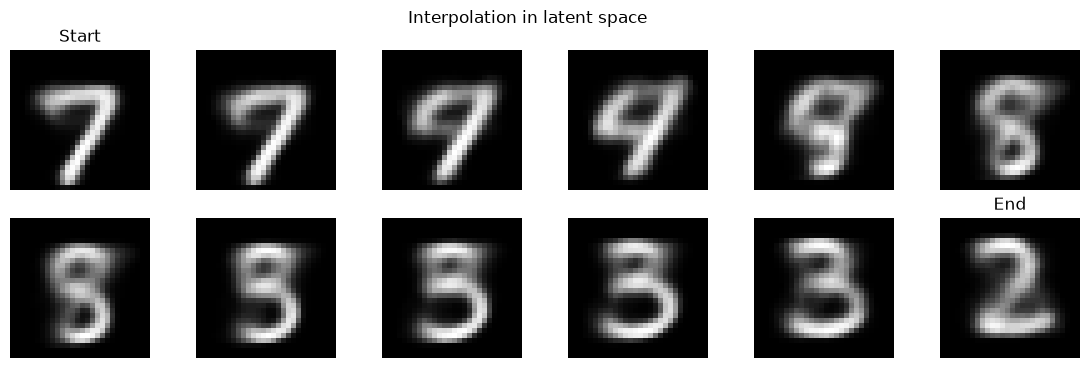

In [10]:
def interpolate(model, x1, x2, steps=10):
    """Линейная интерполяция между двумя изображениями в латентном пространстве."""
    model.eval()
    with torch.no_grad():
        x1 = x1.view(1, -1).to(device)
        x2 = x2.view(1, -1).to(device)
        mu1, _ = model.encode(x1)
        mu2, _ = model.encode(x2)
        # Интерполируем между mu1 и mu2
        alphas = np.linspace(0, 1, steps)
        interp_zs = torch.stack([(1-alpha)*mu1 + alpha*mu2 for alpha in alphas])
        interp_recon = model.decode(interp_zs).cpu().view(steps, 28, 28)
    return interp_recon

# Возьмём две случайные картинки из теста
test_iter = iter(test_loader)
images, labels = next(test_iter)
img1, img2 = images[0], images[1]

interp_images = interpolate(model, img1, img2, steps=12)

plt.figure(figsize=(14,4))
for i, img in enumerate(interp_images):
    plt.subplot(2,6,i+1)
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    if i == 0:
        plt.title('Start')
    elif i == len(interp_images)-1:
        plt.title('End')
plt.suptitle('Interpolation in latent space')
plt.show()

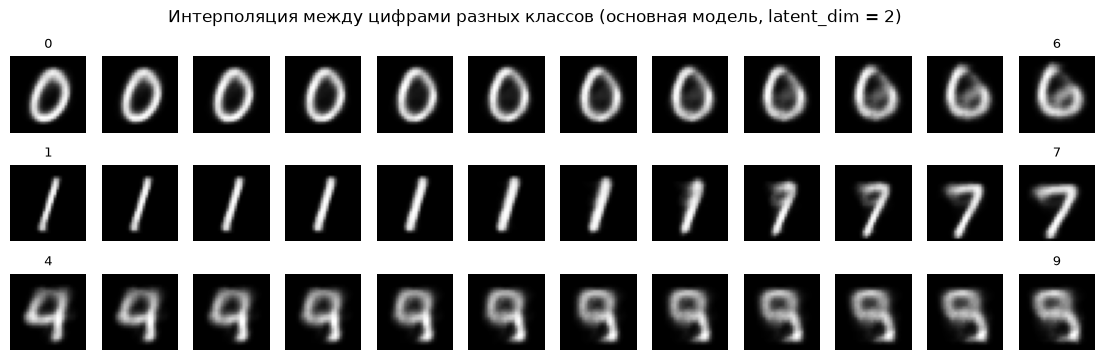

In [11]:
# Интерполяция между цифрами разных классов (среди первых тестовых изображений берём пары 0->6, 1->7, 4->9)
imgs_b, labs_b = images.clone(), labels.clone()   # сохраним этот батч: ниже переменная labels будет переопределена

def first_index(lbl, digit):
    return int((lbl == digit).nonzero()[0])

fig, axes = plt.subplots(3, 12, figsize=(14, 4))
for row, (a, b) in enumerate([(0, 6), (1, 7), (4, 9)]):
    seq = interpolate(model, imgs_b[first_index(labs_b, a)], imgs_b[first_index(labs_b, b)], steps=12)
    for k in range(12):
        axes[row, k].imshow(seq[k], cmap='gray'); axes[row, k].axis('off')
    axes[row, 0].set_title(f'{a}', fontsize=9); axes[row, 11].set_title(f'{b}', fontsize=9)
plt.suptitle('Интерполяция между цифрами разных классов (основная модель, latent_dim = 2)')
plt.show()

## 6. Визуализация латентного пространства (2D)

Уменьшим размерность латентного пространства до 2 (или используем t-SNE) и посмотрим, как распределены цифры.

Epoch 1, Loss: 163.0777


Epoch 2, Loss: 163.2353


Epoch 3, Loss: 164.6516


Epoch 4, Loss: 147.5454


Epoch 5, Loss: 156.8889


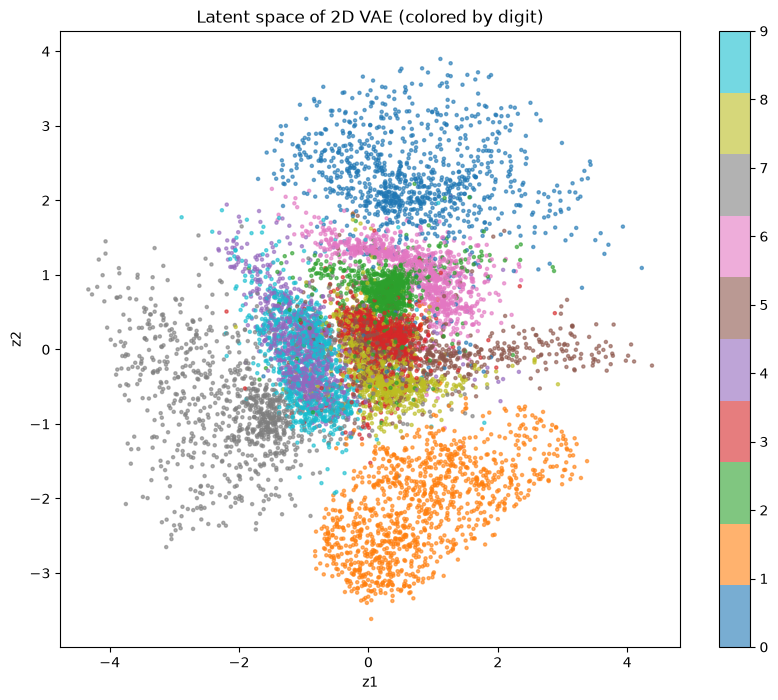

In [12]:
# Для визуализации обучим модель с latent_dim = 2 (или возьмём текущую и применим PCA/t-SNE)
# Но проще обучить маленькую модель с latent_dim=2, если есть время.
# Здесь мы просто покажем пример, как собрать латентные коды для тестовых данных.

model_2d = VAE(input_dim=784, hidden_dim=256, latent_dim=2).to(device)
optimizer_2d = optim.Adam(model_2d.parameters(), lr=1e-3)
# Обучим быстро 5 эпох (для демонстрации)
for epoch in range(S(5, 1)):
    model_2d.train()
    for data, _ in train_loader:
        data = data.view(data.size(0), -1).to(device)
        optimizer_2d.zero_grad()
        recon, mu, log_var = model_2d(data)
        loss = vae_loss(recon, data, mu, log_var)
        loss.backward()
        optimizer_2d.step()
    print(f'Epoch {epoch+1}, Loss: {loss.item():.4f}')

# Соберём латентные коды для тестовой выборки
model_2d.eval()
latent_codes = []
labels_list = []
with torch.no_grad():
    for data, target in test_loader:
        data = data.view(data.size(0), -1).to(device)
        mu, _ = model_2d.encode(data)
        latent_codes.append(mu.cpu().numpy())
        labels_list.append(target.numpy())
latent_codes = np.concatenate(latent_codes)
labels = np.concatenate(labels_list)

plt.figure(figsize=(10,8))
scatter = plt.scatter(latent_codes[:,0], latent_codes[:,1], c=labels, cmap='tab10', alpha=0.6, s=5)
plt.colorbar(scatter)
plt.xlabel('z1')
plt.ylabel('z2')
plt.title('Latent space of 2D VAE (colored by digit)')
plt.show()

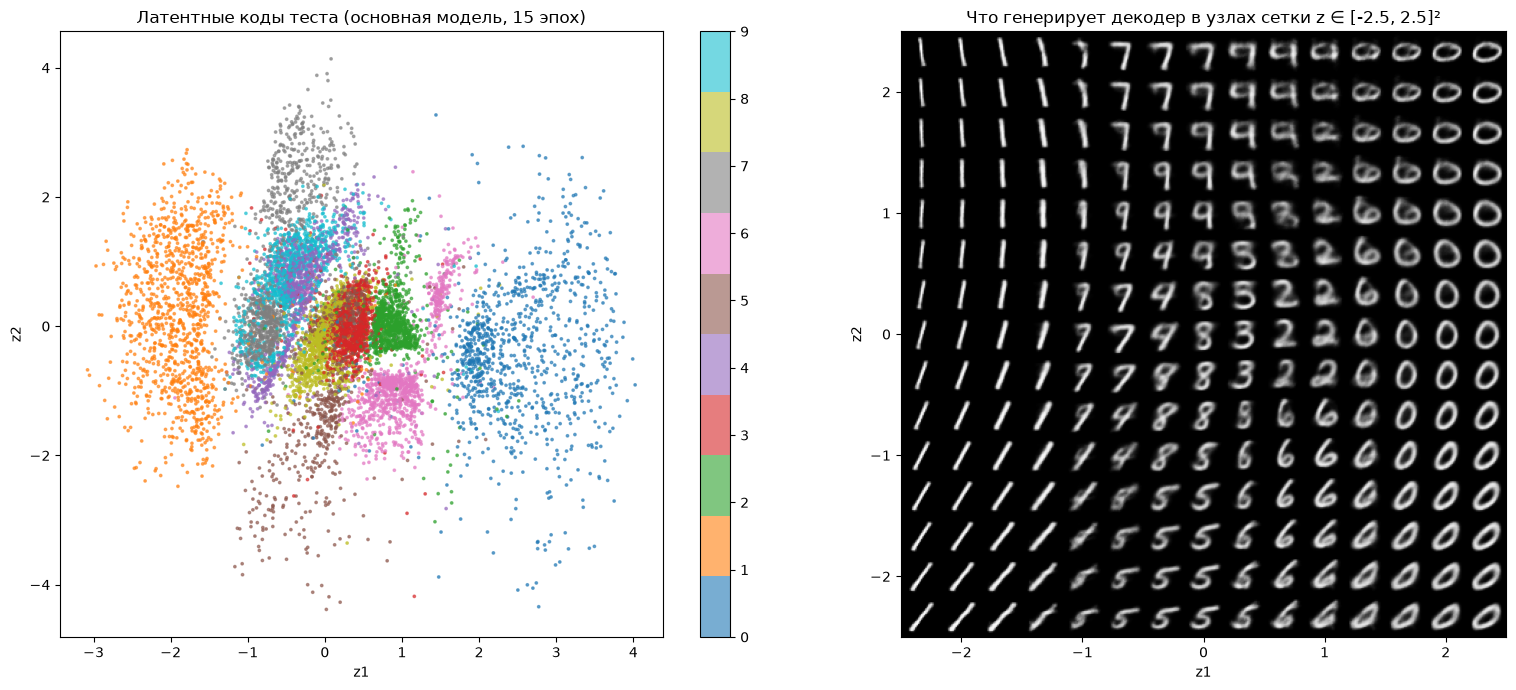

среднее латентных кодов: [0.126 0.035], std: [1.18  1.011] (априорное N(0, 1))


In [13]:
# Латентное пространство основной модели (обучалась 15 эпох) и «карта» того, что декодер рисует в каждой точке
model.eval()
codes, labs = [], []
with torch.no_grad():
    for data, target in test_loader:
        mu, _ = model.encode(data.view(data.size(0), -1).to(device))
        codes.append(mu.cpu().numpy()); labs.append(target.numpy())
codes, labs = np.concatenate(codes), np.concatenate(labs)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
sc = axes[0].scatter(codes[:, 0], codes[:, 1], c=labs, cmap='tab10', s=3, alpha=0.6)
plt.colorbar(sc, ax=axes[0]); axes[0].set_title('Латентные коды теста (основная модель, 15 эпох)')
axes[0].set_xlabel('z1'); axes[0].set_ylabel('z2')
n = 15
grid = np.linspace(-2.5, 2.5, n)                  # квантиль ±2.5σ стандартного нормального распределения
canvas = np.zeros((28 * n, 28 * n))
with torch.no_grad():
    for i, yv in enumerate(grid[::-1]):
        for j, xv in enumerate(grid):
            canvas[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = model.decode(torch.tensor([[xv, yv]], dtype=torch.float32, device=device)).view(28, 28).cpu().numpy()
axes[1].imshow(canvas, cmap='gray', extent=[-2.5, 2.5, -2.5, 2.5])
axes[1].set_title('Что генерирует декодер в узлах сетки z ∈ [-2.5, 2.5]²'); axes[1].set_xlabel('z1'); axes[1].set_ylabel('z2')
plt.tight_layout(); plt.show()
print(f"среднее латентных кодов: {codes.mean(0).round(3)}, std: {codes.std(0).round(3)} (априорное N(0, 1))")

**Обучение** (latent_dim = 2, 15 эпох, 49 с). Loss на изображение падает с 187,8 до 143,4 на обучении и со 166,2 до 144,0 на тесте. Кривые почти совпадают с 4-й эпохи — переобучения нет. Основное снижение приходится на первые 3–4 эпохи, дальше оно замедляется: с 1,5–2 за эпоху до 0,4–0,5 к концу обучения. На тесте реконструкция (BCE) — 136,6, KL — 6,45.

**Реконструкции** с двумерным кодом размыты, и часть цифр восстанавливается как другая цифра. На 15-й эпохе «2» превращается в подобие «3», «3» — в «8», «4» становится похожей на «9». Двух чисел мало, чтобы сохранить начертание конкретной цифры: модель запоминает скорее «типичную» цифру области кода.

**Генерация.** Почти все 64 картинки из $z \sim \mathcal N(0, I)$ похожи на цифры, но размыты, встречаются промежуточные формы между 3, 5 и 8 и между 4 и 9. По вспомогательному классификатору (точность 0,961 на тесте MNIST) 59 % из 1 000 сэмплов распознаются уверенно (вероятность > 0,9), среди них есть все 10 цифр.

**Интерполяция.**
- **0 → 6** — плавный переход: овал постепенно сужается сверху и превращается в петлю шестёрки.
- **1 → 7** — первые 7 кадров остаются единицей, затем за 2–3 кадра появляется перекладина семёрки. Переход есть, но неравномерный: большая часть пути проходит по области единиц, а смена формы происходит за 2–3 кадра.
- **4 → 9** — уже начальная картинка больше похожа на 9, чем на 4, и меняется мало: коды этих цифр в латентном пространстве перекрываются.

**Латентное пространство.** Средние кодов тестовых изображений — (0,13; 0,04), стандартные отклонения — 1,18 и 1,01, то есть распределение кодов близко к априорному $\mathcal N(0, I)$, как и требует KL-слагаемое. Хорошо отделены 1 (слева), 0 (справа), 7 (вверху) и 5 (внизу). 4 и 9 почти полностью перекрываются, 3, 5 и 8 соседствуют в центре. Карта декодера по сетке $[-2{,}5;\,2{,}5]^2$ показывает то же: каждая точка плоскости даёт какую-то цифру, а соседние цифры плавно перетекают друг в друга (1 → 7 → 9, 5 → 6 → 0). Модель из исходного кода практики (5 эпох) даёт похожую картину — 0, 1 и 7 отдельно, 4/9 и 3/5/8 вместе, — только кластеры повернуты иначе: направления осей латентного пространства ничем не закреплены и зависят от случайной инициализации.

## 7. **Задание для самостоятельной работы**:

Попробуйте модифицировать код и ответить на вопросы:<br>
4. **Другой датасет**: попробуйте обучить VAE на Fashion-MNIST или CIFAR-10 (для CIFAR-10 нужно перейти к цветным изображениям и использовать MSE или Gaussian decoder). Можно нейросетью изменения сгенерировать.

**По желанию:**
1. **β-VAE**: измените коэффициент `beta` в функции потерь на значения 0.1, 4, 10. Как меняются реконструкции и качество генерации? Почему?
2. **Размерность латентного пространства**: попробуйте `latent_dim = 2, 5, 50`. Как это влияет на качество реконструкции и гладкость интерполяций?
3. **Архитектура**: добавьте ещё один скрытый слой в энкодер/декодер или используйте сверточные слои (для этого потребуется изменить входные размеры).

👈 *Эти эксперименты помогут глубже понять, как работает VAE и какие факторы влияют на его поведение.*

### Вспомогательные функции для экспериментов

Чтобы сравнивать варианты не только «на глаз», для каждой модели на тестовой выборке считаются средние по изображению **BCE** (качество реконструкции) и **KL** (насколько распределение кодов близко к N(0, I)). Качество генерации оценивается небольшим классификатором цифр (MLP, обучен здесь же): для 1 000 случайных $z \sim \mathcal N(0, I)$ считается доля картинок, которые он относит к какой-либо цифре с уверенностью > 0,9, и сколько разных цифр среди них встречается.

In [14]:
def train_vae(model, train_loader, epochs=15, beta=1.0, lr=1e-3, flatten=True, verbose=False):
    model.to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    t0 = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        for data, _ in train_loader:
            data = data.to(device)
            x = data.view(data.size(0), -1) if flatten else data
            opt.zero_grad()
            recon, mu, log_var = model(x)
            loss = vae_loss(recon.view_as(x), x, mu, log_var, beta)
            loss.backward()
            opt.step()
        if verbose:
            print(f'  эпоха {epoch + 1}: loss {loss.item():.2f}')
    return time.perf_counter() - t0

@torch.no_grad()
def eval_parts(model, loader, flatten=True):
    """Средние по изображению BCE (реконструкция по mu) и KL на выборке."""
    model.eval()
    bce, kl, n = 0.0, 0.0, 0
    for data, _ in loader:
        data = data.to(device)
        x = data.view(data.size(0), -1) if flatten else data
        mu, log_var = model.encode(x)
        recon = model.decode(mu).view_as(x)
        bce += F.binary_cross_entropy(recon, x, reduction='sum').item()
        kl += (-0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp())).item()
        n += x.size(0)
    return bce / n, kl / n

# Вспомогательный классификатор цифр MNIST для оценки сгенерированных картинок
torch.manual_seed(0)
clf = nn.Sequential(nn.Flatten(), nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 10)).to(device)
opt_c = optim.Adam(clf.parameters(), lr=1e-3)
for epoch in range(S(2, 1)):
    for data, target in train_loader:
        data, target = data.to(device), target.to(device)
        opt_c.zero_grad(); F.cross_entropy(clf(data), target).backward(); opt_c.step()
clf.eval()
with torch.no_grad():
    clf_acc = np.mean([(clf(d.to(device)).argmax(1).cpu() == t).float().mean().item() for d, t in test_loader])
print(f'точность вспомогательного классификатора на тесте MNIST: {clf_acc:.4f}')

@torch.no_grad()
def sample_quality(model, latent_dim, n=1000, seed=0):
    g = torch.Generator().manual_seed(seed)
    z = torch.randn(n, latent_dim, generator=g).to(device)
    x = model.decode(z).view(n, 1, 28, 28)
    p = F.softmax(clf(x), dim=1).cpu()
    x = x.cpu()
    conf = p.max(1).values
    confident = conf > 0.9
    digits = p.argmax(1)[confident]
    return confident.float().mean().item(), len(torch.unique(digits)), x[:16]

def show_row(axes, imgs):
    for ax, im in zip(axes, imgs):
        ax.imshow(im.view(28, 28), cmap='gray'); ax.axis('off')

bce0, kl0 = eval_parts(model, test_loader)
q0, nd0, _ = sample_quality(model, 2)
print(f'основная модель (latent=2, β=1, 15 эпох): BCE = {bce0:.1f}, KL = {kl0:.2f}, '
      f'уверенно распознанных сэмплов {q0:.1%}, разных цифр среди них: {nd0}')

точность вспомогательного классификатора на тесте MNIST: 0.9606


основная модель (latent=2, β=1, 15 эпох): BCE = 136.6, KL = 6.45, уверенно распознанных сэмплов 59.0%, разных цифр среди них: 10


### Задание 4. VAE на Fashion-MNIST

Та же модель (MLP-энкодер и декодер, BCE, β = 1, 15 эпох), только данные другие. Обучены две версии: с `latent_dim = 2` (чтобы нарисовать латентное пространство) и `latent_dim = 20` (качество реконструкции).

In [15]:
f_train = datasets.FashionMNIST(root=DATA, train=True, download=True, transform=transform)
f_test = datasets.FashionMNIST(root=DATA, train=False, download=True, transform=transform)
if SMOKE:   # только быстрая проверка: крошечные подвыборки
    f_train, f_test = Subset(f_train, range(1024)), Subset(f_test, range(512))
f_train_loader = DataLoader(f_train, batch_size=128, shuffle=True)
f_test_loader = DataLoader(f_test, batch_size=128, shuffle=False)
F_CLASSES = ['футболка', 'брюки', 'свитер', 'платье', 'пальто', 'сандалии', 'рубашка', 'кроссовки', 'сумка', 'ботинки']

f_models = {}
for ld in [2, 20]:
    torch.manual_seed(42)
    f_models[ld] = VAE(input_dim=784, hidden_dim=256, latent_dim=ld)
    t = train_vae(f_models[ld], f_train_loader, epochs=S(15, 1))
    bce, kl = eval_parts(f_models[ld], f_test_loader)
    print(f'Fashion-MNIST, latent_dim = {ld:2d}: BCE = {bce:.1f}, KL = {kl:.2f}, -ELBO = {bce + kl:.1f}  ({t:.0f} с)')

Fashion-MNIST, latent_dim =  2: BCE = 251.0, KL = 6.37, -ELBO = 257.4  (33 с)


Fashion-MNIST, latent_dim = 20: BCE = 226.0, KL = 12.71, -ELBO = 238.7  (35 с)


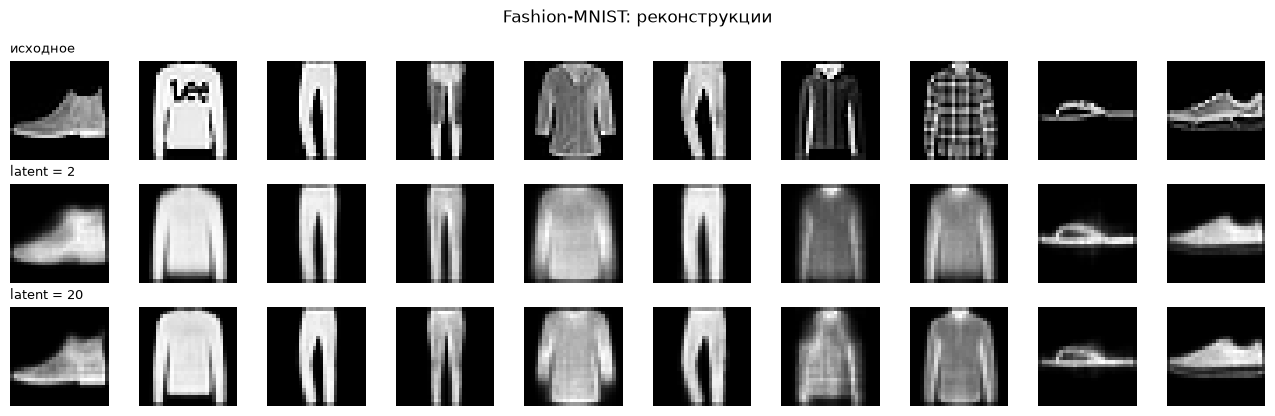

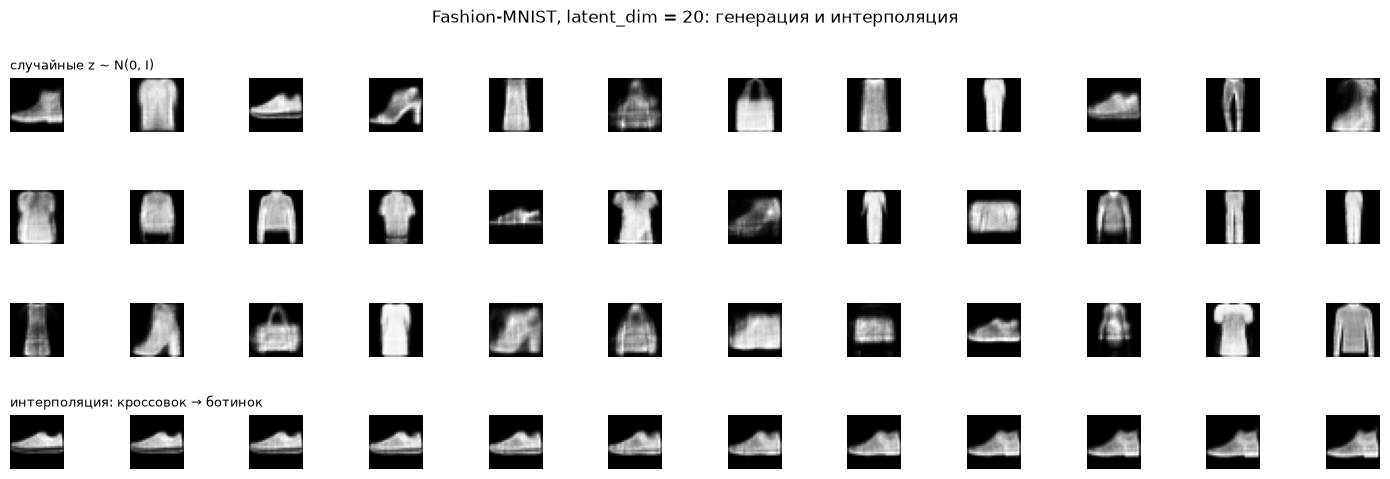

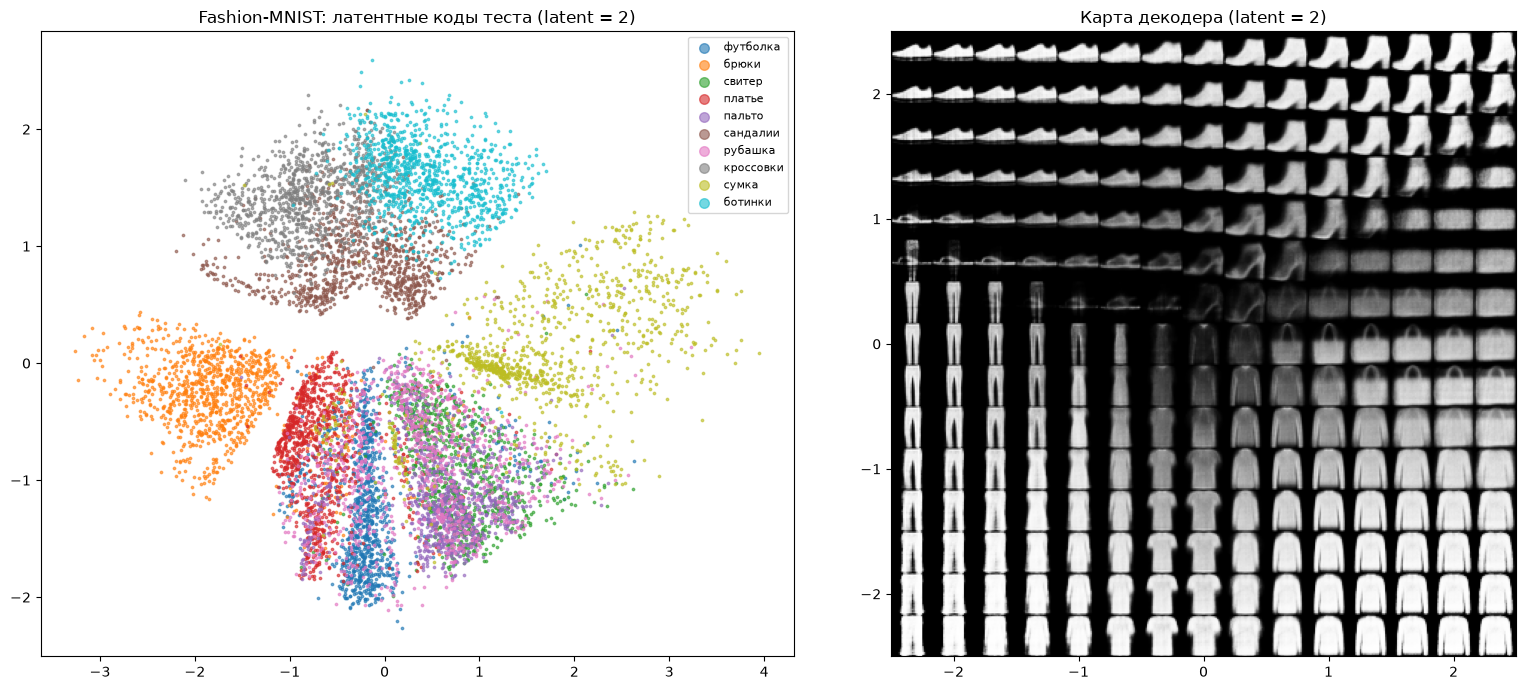

In [16]:
# Реконструкции тестовых изображений: исходник / latent=2 / latent=20
fx, fy = next(iter(f_test_loader))
fig, axes = plt.subplots(3, 10, figsize=(13, 4.2))
with torch.no_grad():
    rec = {ld: f_models[ld].decode(f_models[ld].encode(fx[:10].view(10, -1).to(device))[0]).cpu() for ld in [2, 20]}
show_row(axes[0], fx[:10]); show_row(axes[1], rec[2]); show_row(axes[2], rec[20])
for ax, t in zip(axes[:, 0], ['исходное', 'latent = 2', 'latent = 20']):
    ax.set_title(t, fontsize=9, loc='left')
plt.suptitle('Fashion-MNIST: реконструкции'); plt.tight_layout(); plt.show()

# Генерация из N(0, I) и интерполяция (latent = 20)
fig, axes = plt.subplots(4, 12, figsize=(14, 5))
with torch.no_grad():
    samples = f_models[20].decode(torch.randn(36, 20).to(device)).view(36, 28, 28).cpu()
for k, ax in enumerate(axes[:3].flat):
    ax.imshow(samples[k], cmap='gray'); ax.axis('off')
i_a, i_b = int((fy == 7).nonzero()[0]), int((fy == 9).nonzero()[0])      # кроссовок -> ботинок
seq = interpolate(f_models[20], fx[i_a], fx[i_b], steps=12)
for k in range(12):
    axes[3, k].imshow(seq[k], cmap='gray'); axes[3, k].axis('off')
axes[0, 0].set_title('случайные z ~ N(0, I)', fontsize=9, loc='left')
axes[3, 0].set_title('интерполяция: кроссовок → ботинок', fontsize=9, loc='left')
plt.suptitle('Fashion-MNIST, latent_dim = 20: генерация и интерполяция'); plt.tight_layout(); plt.show()

# Латентное пространство (latent = 2) и карта декодера
codes_f, labs_f = [], []
with torch.no_grad():
    for data, target in f_test_loader:
        codes_f.append(f_models[2].encode(data.view(data.size(0), -1).to(device))[0].cpu().numpy()); labs_f.append(target.numpy())
codes_f, labs_f = np.concatenate(codes_f), np.concatenate(labs_f)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for c in range(10):
    m_ = labs_f == c
    axes[0].scatter(codes_f[m_, 0], codes_f[m_, 1], s=3, alpha=0.6, label=F_CLASSES[c], color=plt.cm.tab10(c))
axes[0].legend(markerscale=4, fontsize=8); axes[0].set_title('Fashion-MNIST: латентные коды теста (latent = 2)')
canvas = np.zeros((28 * n, 28 * n))
with torch.no_grad():
    for i, yv in enumerate(grid[::-1]):
        for j, xv in enumerate(grid):
            canvas[i * 28:(i + 1) * 28, j * 28:(j + 1) * 28] = f_models[2].decode(torch.tensor([[xv, yv]], dtype=torch.float32, device=device)).view(28, 28).cpu().numpy()
axes[1].imshow(canvas, cmap='gray', extent=[-2.5, 2.5, -2.5, 2.5]); axes[1].set_title('Карта декодера (latent = 2)')
plt.tight_layout(); plt.show()

| latent_dim | BCE | KL | −ELBO | время |
|---|---|---|---|---|
| 2 | 251,0 | 6,37 | 257,4 | 33 с |
| 20 | 226,0 | 12,71 | **238,7** | 35 с |

- **Числа нельзя сравнивать с MNIST напрямую.** В Fashion-MNIST много пикселей среднего серого уровня, а для таких пикселей BCE не обращается в ноль даже при идеальной реконструкции. Сравнивать можно только модели на одних данных.
- **Реконструкции.** Обе модели передают силуэт и общую яркость вещи, но теряют мелкие детали: надпись на свитере, клетку на рубашке. При latent = 2 первая кроссовка восстанавливается как ботинок, а рубашки и пальто — как почти одинаковые кофты. При latent = 20 лучше видны форма обуви, воротник, длина рукава — отсюда BCE на 25 меньше. Цена — вдвое большая KL (12,7 против 6,4), но −ELBO всё равно лучше на 19.
- **Генерация (latent = 20)** даёт узнаваемые вещи всех основных типов — ботинки, кроссовки, туфли на каблуке, сумки, брюки, платья, футболки, свитера, — но размытые, есть и неопределённые картинки. Интерполяция «кроссовок → ботинок» плавная: подошва сохраняется, верх постепенно поднимается.
- **Латентное пространство (latent = 2)** разделено на группы по типу вещи. Обувь (кроссовки, сандалии, ботинки) — вверху, брюки — слева, сумки — справа. Верхняя одежда (свитер, пальто, рубашка) образует одно перемешанное облако, рядом с ним — футболки и платья. Карта декодера устроена так же: обувь в верхней части, одежда внизу, сумки справа, между ними плавные переходы.
- **Итог.** Тот же VAE без изменений работает и на Fashion-MNIST, но двух латентных измерений здесь меньше, чем нужно: вещи сложнее по форме и текстуре, чем цифры, и при latent = 20 качество заметно лучше.

### По желанию 1. β-VAE

MNIST, `latent_dim = 10`, по 15 эпох (как в основной части) для β = 0,1; 1; 4; 10. Латентная размерность 10 взята для того, чтобы можно было посчитать, сколько измерений кода остаются «активными» при разных β (при двух измерениях такое сравнение почти лишено смысла). Коэффициент β стоит при KL-слагаемом функции потерь `vae_loss`.

    β      BCE      KL  уверенных сэмплов  разных цифр  активных измерений z  время, с
  0.1     79.7   33.48              17.7%           10                 10/10        34
  1.0     81.2   18.65              42.2%           10                 10/10        35
  4.0    102.8    8.01              57.6%           10                  6/10        34
 10.0    132.9    3.35              53.8%           10                  4/10        35


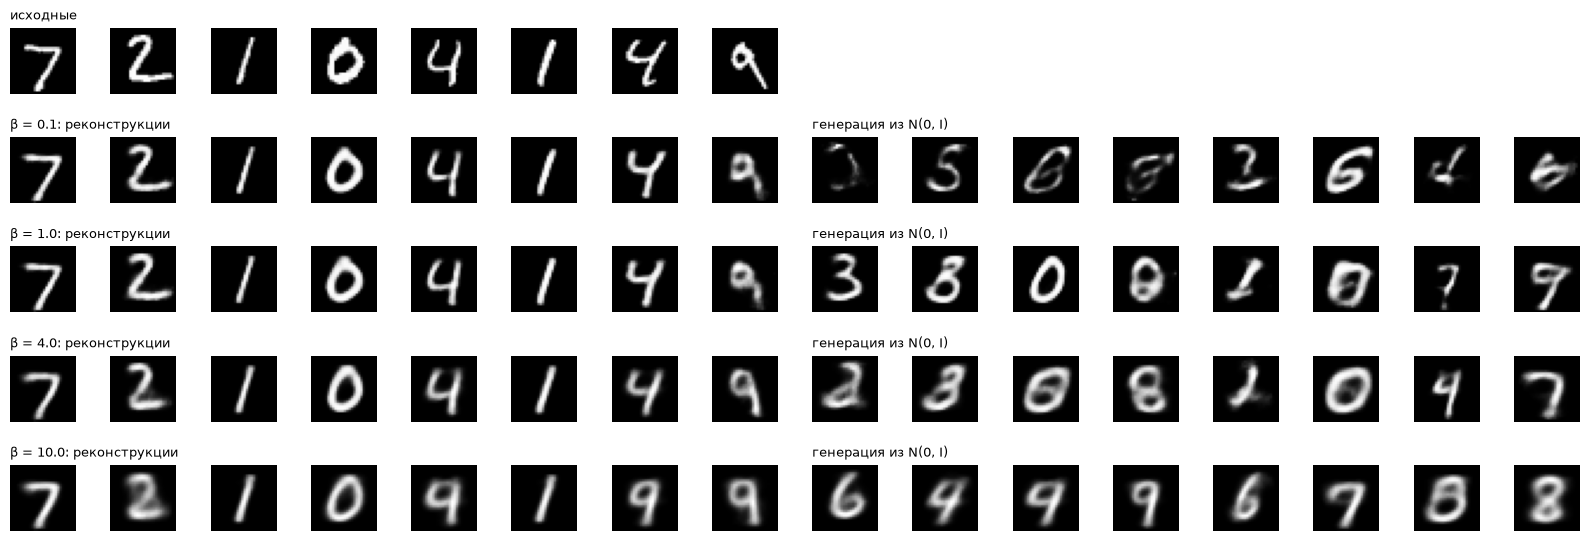

In [17]:
beta_models, beta_rows = {}, []
for b in [0.1, 1.0, 4.0, 10.0]:
    torch.manual_seed(42)
    m = VAE(input_dim=784, hidden_dim=256, latent_dim=10)
    t = train_vae(m, train_loader, epochs=S(15, 1), beta=b)
    bce, kl = eval_parts(m, test_loader)
    q, nd, smp = sample_quality(m, 10)
    with torch.no_grad():
        xb_ = next(iter(test_loader))[0]
        _, lv = m.encode(xb_.view(xb_.size(0), -1).to(device))
    active = int((lv.exp().mean(0).cpu() < 0.9).sum())    # «активные» измерения: дисперсия кода заметно меньше 1
    beta_models[b] = (m, smp)
    beta_rows.append((b, bce, kl, q, nd, active, t))
print(f"{'β':>5} {'BCE':>8} {'KL':>7} {'уверенных сэмплов':>18} {'разных цифр':>12} {'активных измерений z':>21} {'время, с':>9}")
for b, bce, kl, q, nd, act_, t in beta_rows:
    print(f"{b:>5} {bce:>8.1f} {kl:>7.2f} {q:>18.1%} {nd:>12d} {act_:>18d}/10 {t:>9.0f}")

x8 = next(iter(test_loader))[0][:8]
fig, axes = plt.subplots(5, 16, figsize=(16, 5.6))
show_row(axes[0, :8], x8); axes[0, 0].set_title('исходные', fontsize=9, loc='left')
for ax in axes[0, 8:]: ax.axis('off')
for r, b in enumerate(beta_models, start=1):
    m, smp = beta_models[b]
    with torch.no_grad():
        rec = m.decode(m.encode(x8.view(8, -1).to(device))[0]).cpu()
    show_row(axes[r, :8], rec); show_row(axes[r, 8:], smp[:8])
    axes[r, 0].set_title(f'β = {b}: реконструкции', fontsize=9, loc='left'); axes[r, 8].set_title('генерация из N(0, I)', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

| β | BCE | KL | уверенно распознано сэмплов | активных измерений z |
|---|---|---|---|---|
| 0,1 | **79,7** | 33,48 | 17,7 % | 10 из 10 |
| 1 | 81,2 | 18,65 | 42,2 % | 10 из 10 |
| 4 | 102,8 | 8,01 | **57,6 %** | 6 из 10 |
| 10 | 132,9 | 3,35 | 53,8 % | 4 из 10 |

Среди уверенно распознанных сэмплов при всех β есть все 10 цифр.

- **Реконструкции** с ростом β ухудшаются. При β = 0,1 и 1 они почти не отличаются от исходных (BCE 80–81). При β = 4 штрихи размываются. При β = 10 цифры теряют индивидуальность: обе «4» восстанавливаются как «9», а «2» сильно размыта.
- **Генерация** ведёт себя наоборот. При β = 0,1 многие сэмплы — обрывки штрихов и смешанные формы, уверенно распознаётся только 18 %. При β = 4 — 58 %, лучший результат. При β = 10 картинки гладкие и похожи на «средние» цифры, доля немного снижается (54 %), по-видимому, потому что размытые изображения классификатор реже распознаёт с уверенностью > 0,9.
- **Почему.** Функция потерь — это BCE + β·KL. β задаёт баланс между точностью реконструкции и близостью распределения кодов к $\mathcal N(0, I)$.
  - При малом β модель работает почти как обычный автокодировщик: коды хорошо описывают изображения (KL 33), но занимают не всю область, откуда берутся $z \sim \mathcal N(0, I)$. Случайный $z$ часто попадает туда, где декодер не обучался, отсюда плохая генерация.
  - При большом β модели выгодно не использовать часть измерений вовсе: их распределение совпадает с априорным, и вклад в KL нулевой. «Активных» измерений (тех, где средняя по изображениям дисперсия кода меньше 0,9, то есть заметно меньше априорной единицы) остаётся 6 при β = 4 и 4 при β = 10. Информации об изображении в коде меньше, поэтому реконструкции хуже. Зато распределение кодов ближе к априорному, и случайные $z$ дают правдоподобные цифры.

### По желанию 2. Размерность латентного пространства

MNIST, β = 1, по 15 эпох для `latent_dim` = 2, 5, 50. Для оценки гладкости интерполяции считается отношение самого большого «скачка» между соседними кадрами к среднему (1 — изменения равномерные; чем больше, тем резче переход в одном месте).

latent      BCE      KL  уверенных сэмплов  разных цифр  макс./средн. скачок  время, с
     2    137.7    6.36              61.2%           10                 1.34        36
     5    103.8   11.67              50.9%           10                 1.39        34
    50     78.5   19.23              42.4%           10                 1.29        35


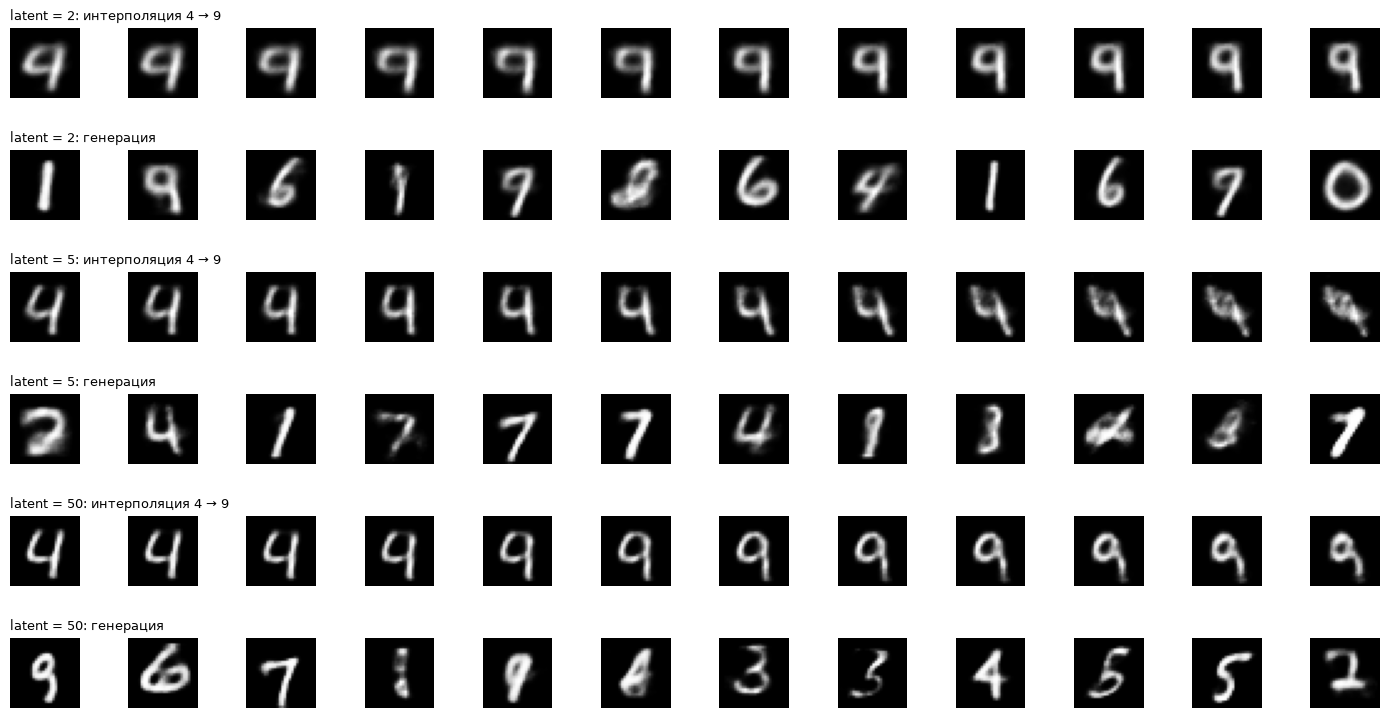

In [18]:
def smoothness(seq):
    d = (seq[1:] - seq[:-1]).flatten(1).norm(dim=1)
    return (d.max() / d.mean()).item()

xa, xb = imgs_b[first_index(labs_b, 4)], imgs_b[first_index(labs_b, 9)]
xc, xd = imgs_b[first_index(labs_b, 1)], imgs_b[first_index(labs_b, 7)]
ld_models, ld_rows = {}, []
for ld in [2, 5, 50]:
    torch.manual_seed(42)
    m = VAE(input_dim=784, hidden_dim=256, latent_dim=ld)
    t = train_vae(m, train_loader, epochs=S(15, 1))
    bce, kl = eval_parts(m, test_loader)
    q, nd, smp = sample_quality(m, ld)
    seqs = [interpolate(m, xa, xb, steps=12), interpolate(m, xc, xd, steps=12)]
    ld_models[ld] = (m, smp, seqs)
    ld_rows.append((ld, bce, kl, q, nd, np.mean([smoothness(s) for s in seqs]), t))
print(f"{'latent':>6} {'BCE':>8} {'KL':>7} {'уверенных сэмплов':>18} {'разных цифр':>12} {'макс./средн. скачок':>20} {'время, с':>9}")
for ld, bce, kl, q, nd, sm, t in ld_rows:
    print(f"{ld:>6} {bce:>8.1f} {kl:>7.2f} {q:>18.1%} {nd:>12d} {sm:>20.2f} {t:>9.0f}")

fig, axes = plt.subplots(6, 12, figsize=(14, 7.5))
for r, ld in enumerate(ld_models):
    m, smp, seqs = ld_models[ld]
    for k in range(12):
        axes[2 * r, k].imshow(seqs[0][k], cmap='gray'); axes[2 * r, k].axis('off')
        axes[2 * r + 1, k].imshow(smp[k].view(28, 28), cmap='gray'); axes[2 * r + 1, k].axis('off')
    axes[2 * r, 0].set_title(f'latent = {ld}: интерполяция 4 → 9', fontsize=9, loc='left')
    axes[2 * r + 1, 0].set_title(f'latent = {ld}: генерация', fontsize=9, loc='left')
plt.tight_layout(); plt.show()

| latent_dim | BCE | KL | уверенно распознано сэмплов | макс./средний скачок интерполяции |
|---|---|---|---|---|
| 2 | 137,7 | 6,36 | **61,2 %** | 1,34 |
| 5 | 103,8 | 11,67 | 50,9 % | 1,39 |
| 50 | **78,5** | 19,23 | 42,4 % | **1,29** |

- **Реконструкция** заметно улучшается с ростом размерности: BCE падает с 138 до 104 и 79. Двух измерений не хватает даже на то, чтобы отличить 4 от 9.
- **Интерполяция 4 → 9.**
  - При latent = 2 все 12 кадров — почти одна и та же девятка: обе картинки кодируются в близкие точки.
  - При latent = 5 четвёрка переходит в девятку, но последние кадры — неразборчивое пятно: тестовая «9» необычной формы при 5 измерениях восстанавливается плохо.
  - При latent = 50 переход полный и чистый — от узнаваемой 4 к 9 с хвостом, как у исходной.

  Отношение максимального скачка к среднему у всех размерностей близко (1,29–1,39): ни в одном случае нет резкого перескока в одном кадре. Эта мера показывает только равномерность изменений, но не то, насколько осмысленны промежуточные картинки, поэтому вывод о качестве интерполяции сделан по самим картинкам.
- **Генерация.** Доля уверенно распознанных сэмплов, наоборот, падает: 61 → 51 → 42 %. При latent = 2 декодер заполняет цифрами всю плоскость (это видно на карте декодера в разделе 6), и любой случайный $z$ даёт размытую, но цифру. С ростом размерности растёт KL (6 → 19), то есть коды дальше от $\mathcal N(0, I)$, и случайные $z$ чаще попадают туда, где декодер даёт смешанные или неправдоподобные формы. Это предположение, отдельно оно не проверялось.
- **Итог.** Малая размерность — гладкое, «заполненное» пространство и узнаваемая, но усреднённая генерация. Большая — точные реконструкции и осмысленные интерполяции между реальными изображениями, но генерация из $\mathcal N(0, I)$ хуже.

### По желанию 3. Свёрточный VAE

Энкодер: две свёртки с шагом 2 (28→14→7), декодер — две транспонированные свёртки (7→14→28). Латентная размерность 10, β = 1, 15 эпох; сравнение — с полносвязным VAE той же латентной размерности (модель β = 1 из опыта с β-VAE).

модель                  параметров      BCE      KL  уверенных сэмплов  время, с
MLP VAE (latent 10)        541,988     81.2   18.65              42.2%        35
Conv VAE (latent 10)        65,589     83.2   19.42              36.1%        44


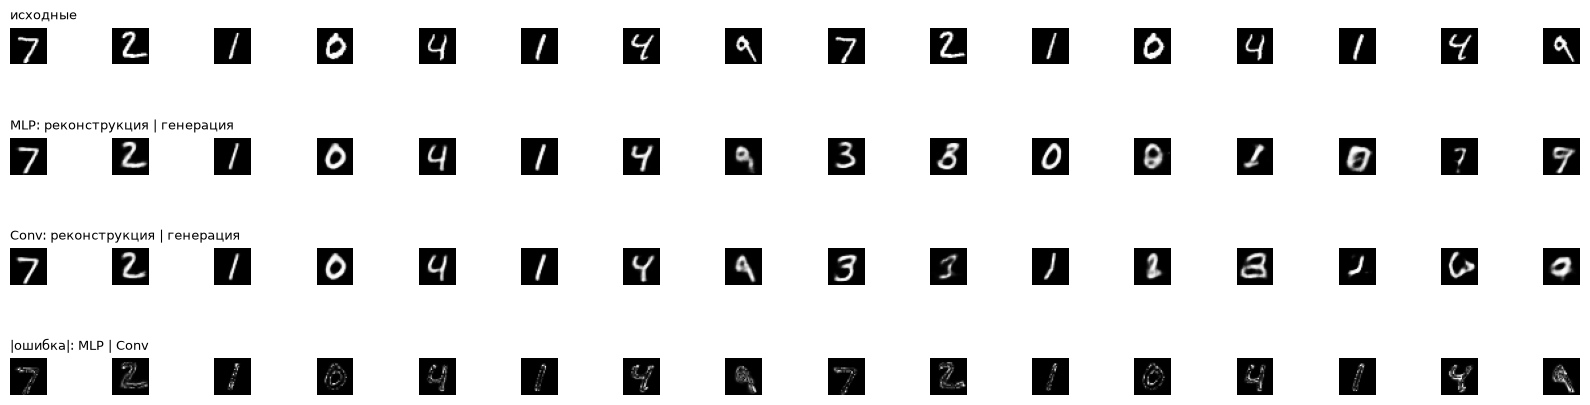

In [19]:
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=10, ch=16):
        super().__init__()
        self.latent_dim = latent_dim
        self.enc = nn.Sequential(
            nn.Conv2d(1, ch, 4, stride=2, padding=1), nn.ReLU(),           # 28 -> 14
            nn.Conv2d(ch, 2 * ch, 4, stride=2, padding=1), nn.ReLU(),      # 14 -> 7
            nn.Flatten(), nn.Linear(2 * ch * 7 * 7, 2 * latent_dim))
        self.dec_fc = nn.Linear(latent_dim, 2 * ch * 7 * 7)
        self.dec = nn.Sequential(
            nn.ReLU(), nn.Unflatten(1, (2 * ch, 7, 7)),
            nn.ConvTranspose2d(2 * ch, ch, 4, stride=2, padding=1), nn.ReLU(),   # 7 -> 14
            nn.ConvTranspose2d(ch, 1, 4, stride=2, padding=1), nn.Sigmoid())     # 14 -> 28

    def encode(self, x):
        x = x.view(-1, 1, 28, 28)
        return self.enc(x).chunk(2, dim=-1)

    def reparameterize(self, mu, log_var):
        return mu + torch.randn_like(mu) * torch.exp(0.5 * log_var)

    def decode(self, z):
        return self.dec(self.dec_fc(z))

    def forward(self, x):
        mu, log_var = self.encode(x)
        return self.decode(self.reparameterize(mu, log_var)), mu, log_var

torch.manual_seed(42)
conv_vae = ConvVAE(latent_dim=10)
t = train_vae(conv_vae, train_loader, epochs=S(15, 1), flatten=False)
bce_c, kl_c = eval_parts(conv_vae, test_loader, flatten=False)
q_c, nd_c, smp_c = sample_quality(conv_vae, 10)
mlp10 = beta_models[1.0][0]
bce_m, kl_m = eval_parts(mlp10, test_loader)
q_m, nd_m, smp_m = sample_quality(mlp10, 10)
n_par = lambda m: sum(p.numel() for p in m.parameters())
print(f"{'модель':<22} {'параметров':>11} {'BCE':>8} {'KL':>7} {'уверенных сэмплов':>18} {'время, с':>9}")
print(f"{'MLP VAE (latent 10)':<22} {n_par(mlp10):>11,} {bce_m:>8.1f} {kl_m:>7.2f} {q_m:>18.1%} {beta_rows[1][-1]:>9.0f}")
print(f"{'Conv VAE (latent 10)':<22} {n_par(conv_vae):>11,} {bce_c:>8.1f} {kl_c:>7.2f} {q_c:>18.1%} {t:>9.0f}")

fig, axes = plt.subplots(4, 16, figsize=(16, 4.6))
with torch.no_grad():
    rec_m = mlp10.decode(mlp10.encode(x8.view(8, -1).to(device))[0]).cpu()
    rec_c = conv_vae.decode(conv_vae.encode(x8.to(device))[0]).cpu()
show_row(axes[0, :8], x8); show_row(axes[0, 8:], x8)
show_row(axes[1, :8], rec_m); show_row(axes[1, 8:], smp_m[:8])
show_row(axes[2, :8], rec_c); show_row(axes[2, 8:], smp_c[:8])
with torch.no_grad():
    show_row(axes[3, :8], (rec_m - x8.view(8, -1)).abs()); show_row(axes[3, 8:], (rec_c.view(8, -1) - x8.view(8, -1)).abs())
for r, t_ in enumerate(['исходные', 'MLP: реконструкция | генерация', 'Conv: реконструкция | генерация', '|ошибка|: MLP | Conv']):
    axes[r, 0].set_title(t_, fontsize=9, loc='left')
plt.tight_layout(); plt.show()

| модель | параметров | BCE | KL | уверенно распознано сэмплов | время |
|---|---|---|---|---|---|
| полносвязный VAE | 541 988 | **81,2** | 18,65 | **42,2 %** | 35 с |
| свёрточный VAE | 65 589 | 83,2 | 19,42 | 36,1 % | 44 с |

- **Реконструкции** у двух моделей почти одинаковые: BCE 81,2 и 83,2, и на картинках разница почти не видна. Карты ошибок у обеих моделей похожи: ошибка сосредоточена на краях штрихов, то есть обе модели «размывают» контур, а не теряют форму.
- **Параметры.** Свёрточная модель достигает этого при в 8 раз меньшем числе параметров (65,6 тыс. против 542 тыс.). Свёртки используют одни и те же веса по всему изображению и учитывают соседство пикселей, а полносвязной сети приходится заучивать каждую связь отдельно.
- **Генерация у свёрточной модели хуже:** 36 % уверенно распознанных сэмплов против 42 %, на картинках больше изогнутых и незаконченных штрихов.
- **Время.** Свёрточная модель обучалась немного дольше (44 с против 35 с), несмотря на меньшее число параметров: по-видимому, потому что каждый вес свёртки применяется во всех позициях изображения и вычислений на один параметр больше.
- **Итог.** При одинаковых 15 эпохах и небольшом числе каналов (16 и 32) свёрточный VAE не лучше полносвязного, но сопоставим с ним при намного меньшем размере. Улучшит ли его результат больше каналов или эпох, здесь не проверялось.

## Заключение

Мы реализовали и обучили VAE на MNIST. Убедились, что модель способна:
- реконструировать входные изображения;
- генерировать новые правдоподобные цифры из случайного шума;
- выполнять плавные интерполяции в латентном пространстве;
- визуализировать структуру латентного пространства.

Это лишь базовый пример; современные VAE используются в самых разных задачах — от генерации изображений до моделирования молекул. Надеемся, что эксперименты помогут вам освоиться с этой техникой.

😊 *Удачных экспериментов!*